**Week 13: University Admissions Assignment**

In [1]:
#Part 1: Libraries and Data
#import the necessary libraries
import pandas as pd #imports pandas
import matplotlib.pyplot as plt #imports matplot
import seaborn as sns #imports seaborn
import plotly.express as px #imports plotly

In [3]:
#lets bring in the data
df = pd.read_excel("applications.xlsx") #reads in the excel file as df
df.head() #lets me take a quick peek at the top of the data

,Applicant,Sex,SAT_ACT,College,Admitted,Enrolled,Extracurricular_Hours
0,1,M,1460,Business & Economics,Yes,No,5
1,2,F,1180,Math & Science,No,No,10
2,3,M,1340,Arts & Letters,Yes,No,7
3,4,M,1190,Business & Economics,No,No,1
4,5,F,1290,Business & Economics,No,No,4


In [4]:
#Part 2: Check the data
df.shape #shows the size of the data rows by columns

(17339, 7)

In [5]:
df.columns #lists out column names

Index(['Applicant', 'Sex', 'SAT_ACT', 'College', 'Admitted', 'Enrolled',
       'Extracurricular_Hours'],
      dtype='str')

In [6]:
#checking for missing data
df.isnull().sum() #sums the number of fields with missing data

Applicant                0
Sex                      0
SAT_ACT                  0
College                  0
Admitted                 0
Enrolled                 0
Extracurricular_Hours    0
dtype: int64

In [7]:
#data looks good, no missing data. lets move on to visualizations

#Part 3: Visuals
#Task 1: Bar Plot
college_counts = df["College"].value_counts() #adds the cumulative number of applications for each college
print(college_counts) #displays results

College
Arts & Letters          6964
Math & Science          6272
Business & Economics    4103
Name: count, dtype: int64


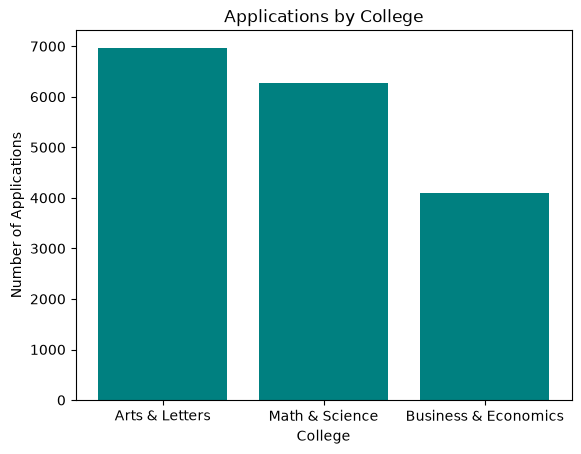

In [17]:
#matplotlib bar plot
plt.bar(college_counts.index, college_counts.values, color = 'teal') #creates bar plot
plt.title("Applications by College") #chart title
plt.xlabel("College") #x axis title
plt.ylabel("Number of Applications") #y axis title
plt.xticks(rotation = 0) #rotates the x axis lables so they are not vertical
plt.show() #displays plot

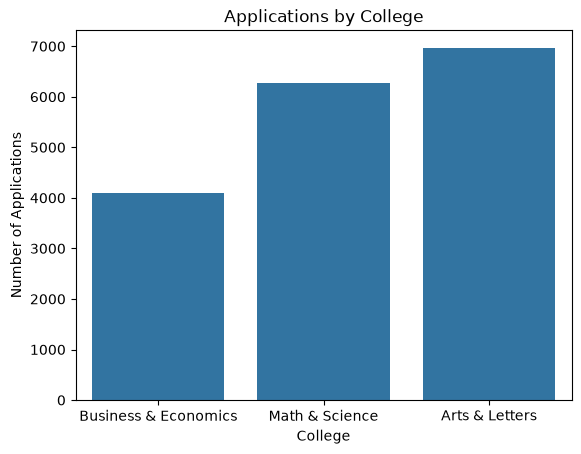

In [9]:
#seaborn bar plot
sns.countplot(data = df, x = "College") #creates bar plot
plt.title("Applications by College") #chart title
plt.xlabel("College") #x axis title
plt.ylabel("Number of Applications") #y axis title
plt.xticks(rotation = 0) #rotates the x axis lables so they are not vertical
plt.show() #displays plot

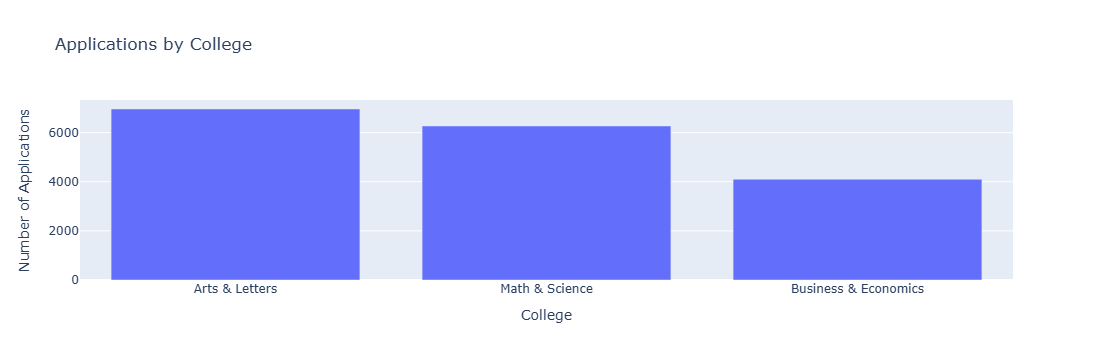

In [10]:
#plotly bar plot
fig = px.bar( #tells it to create a bar plot
    x = college_counts.index, #identifies x axis values
    y = college_counts.values, #identifies y axis values
    labels = {"x": "College", "y": "Number of Applications"}, #labels our x and y axis
    title = "Applications by College" #title the chart
)

fig.show() #displays

**Which college attracts the most applicants? Arts & Letters with 6964 applicants**

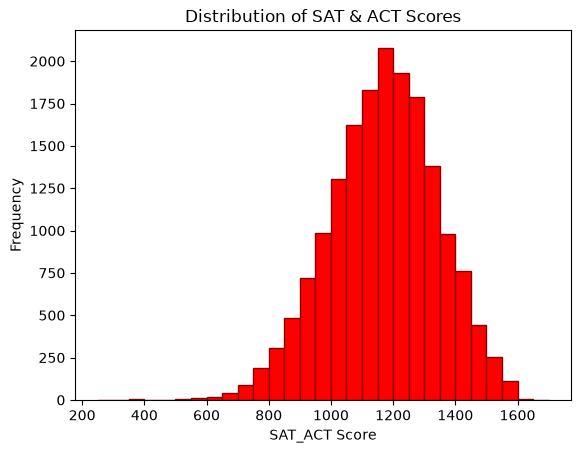

In [14]:
#Task 2: Histograms
#matplotlib histo

plt.hist(df["SAT_ACT"], bins = range(250, 1750 , 50), color = "red", edgecolor = "darkred") #creates a histogram using the SAT_ACT data with bin size 50, ranging from 250 to 1750
plt.title("Distribution of SAT & ACT Scores") #titles our chart
plt.xlabel("SAT_ACT Score") #sets x axis label
plt.ylabel("Frequency") #sets y axis label
plt.show() #displays chart

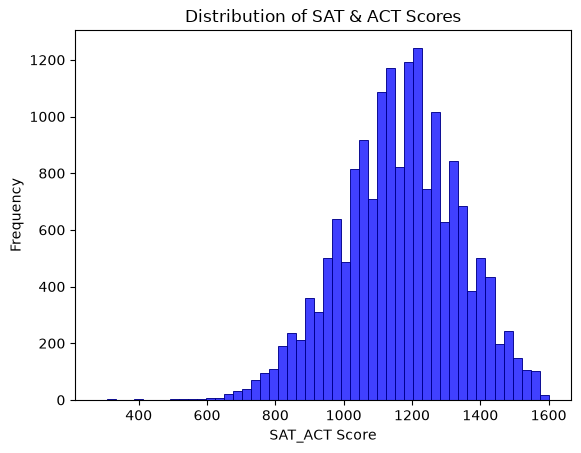

In [16]:
import seaborn as sns
#seaborn histo
sns.histplot( #creates histogram
    data = df, #identifies the data
    x = "SAT_ACT", #sets x axis
    bins = 50, #sets bin width
    color = "blue", #sets bar color
    edgecolor = "darkblue" #sets bar border color
)

plt.title("Distribution of SAT & ACT Scores") #titles our chart
plt.xlabel("SAT_ACT Score") #sets x axis label
plt.ylabel("Frequency") #sets y axis label
plt.show() #displays chart

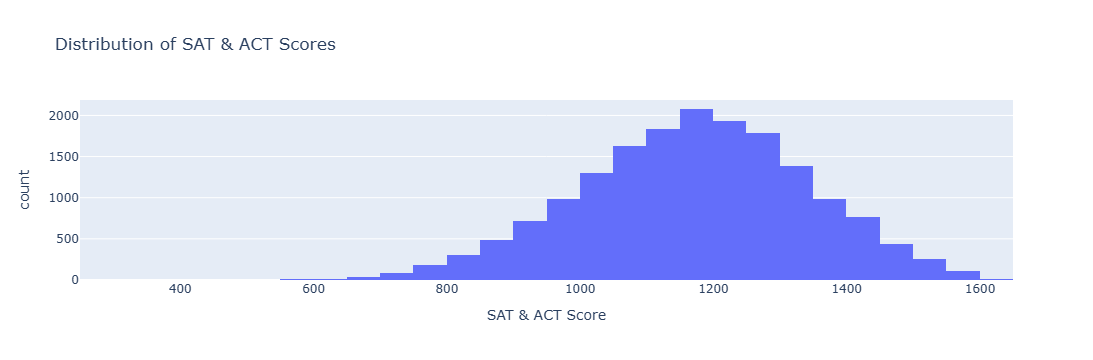

In [40]:
#plotly histo
fig = px.histogram( #creates histogram
    df, #ids data
    x = "SAT_ACT", #sets x axis
    nbins = 27, #sets number of bins,
    title = "Distribution of SAT & ACT Scores",
    labels = {"SAT_ACT": "SAT & ACT Score"}
)

fig.show()

**What is the most common score range? 1150-1190 with 2078 applicants**

In [41]:
#Task 3: Box Plot
#matplotlib box
#we are going to create 3 groups for the data
arts = df[df["College"] == "Arts & Letters"]["SAT_ACT"] #creates arts grouping
math = df[df["College"] == "Math & Science"]["SAT_ACT"] #creates math grouping
business = df[df["College"] == "Business & Economics"]["SAT_ACT"] #creates business grouping

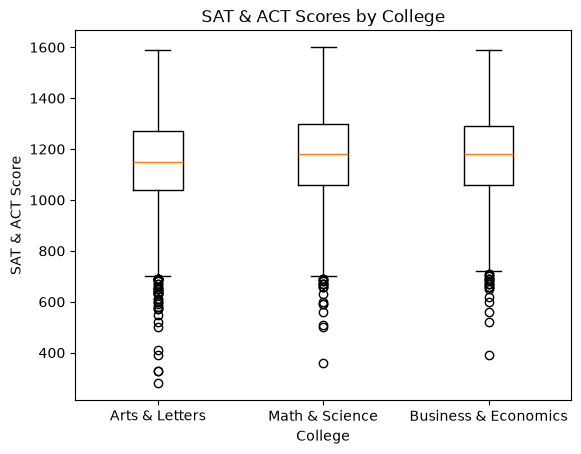

In [44]:
#create our box plot using matplotlib
plt.boxplot(
    [arts, math, business],
    tick_labels = ["Arts & Letters", "Math & Science", "Business & Economics"] ) #creates box plot with labels

plt.title("SAT & ACT Scores by College") #titles plot
plt.xlabel("College") #titles x axis
plt.ylabel("SAT & ACT Score") #titles y axis
plt.show() #displays plot

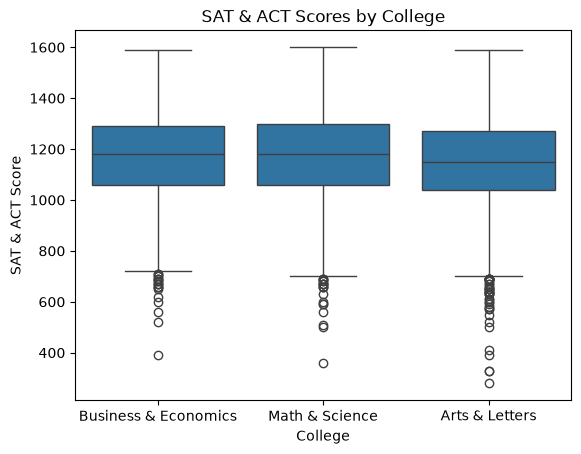

In [46]:
#seaborn box
sns.boxplot( #creates box plot
    data = df, #ids data
    x = "College", #sets x axis
    y = "SAT_ACT") #sets y axis

plt.title("SAT & ACT Scores by College") #titles plot
plt.xlabel("College") #titles x axis
plt.ylabel("SAT & ACT Score") #titles y axis
plt.show() #displays plot


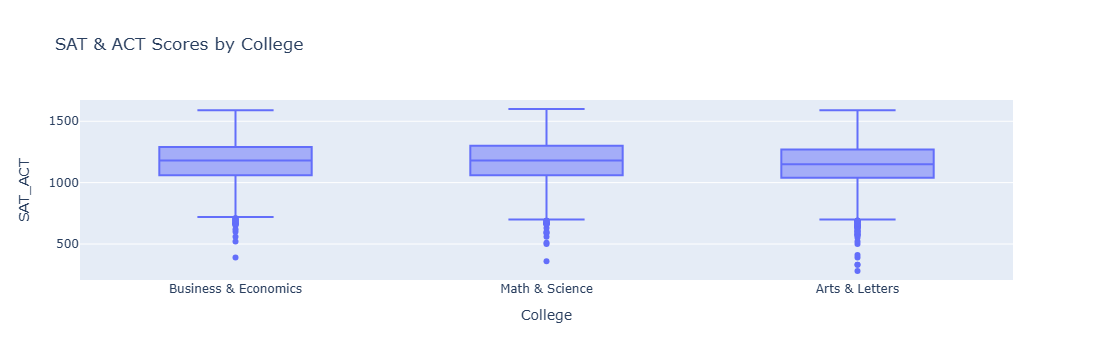

In [47]:
#plotly box
fig = px.box( #creates box plot
    df, #ids data
    x = "College", #sets x axis
    y = "SAT_ACT", #sets y axis
    title = "SAT & ACT Scores by College") #sets a title for the chart

fig.show()

In [48]:
#lets find the mean scores for each college
median_scores = df.groupby("College")["SAT_ACT"].median() #finds the median SAT and ACT scores for each college

print(median_scores) #displays results

College
Arts & Letters          1150.0
Business & Economics    1180.0
Math & Science          1180.0
Name: SAT_ACT, dtype: float64


**Which college has the highest median score? Business & Economics is actually tied for highest average with Math & Science**

In [41]:
df.head() #bringing this down so I can easily see the data without scrolling back up

,Applicant,Sex,SAT_ACT,College,Admitted,Enrolled,Extracurricular_Hours
0,1,M,1460,Business & Economics,Yes,No,5
1,2,F,1180,Math & Science,No,No,10
2,3,M,1340,Arts & Letters,Yes,No,7
3,4,M,1190,Business & Economics,No,No,1
4,5,F,1290,Business & Economics,No,No,4


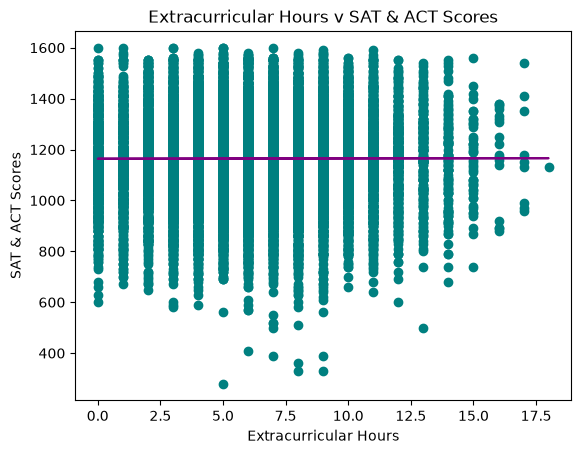

In [32]:
#Part 4: Scatter Plot
#Visualize the relationship between SAT_ACT scores and Extracurricular_Hours. 
#Is there a positive, negative, or no clear relationship?

#first import numpy
import numpy as np

#Matplotlib
plt.scatter(df['Extracurricular_Hours'], df['SAT_ACT'], color = 'teal') #creates the scatter plot with extra curricular hours as the x variable
#and SAT scores as the y variable

#now lets add trendlines and titles
m, b = np.polyfit(df['Extracurricular_Hours'], df['SAT_ACT'], 1) #creates the variables m and b and calculates slope of regression line
plt.plot(df['Extracurricular_Hours'], m * df['Extracurricular_Hours'] + b, color='purple') #creates the trendline based on the variables m and b in purple
plt.title('Extracurricular Hours v SAT & ACT Scores') #adds chart title
plt.xlabel('Extracurricular Hours') #adds x title
plt.ylabel('SAT & ACT Scores') # adds y title
plt.show() #displays the chart


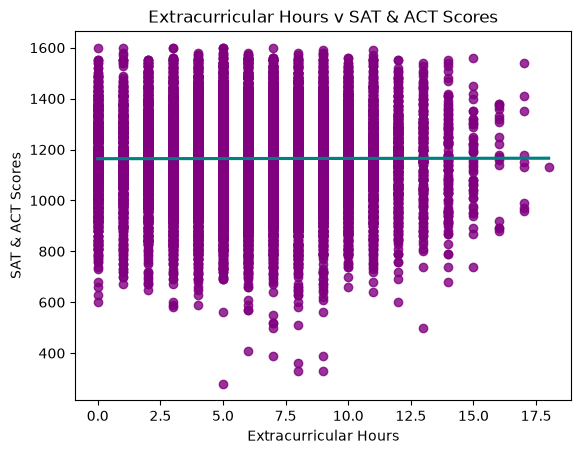

In [33]:
#Repeated with Seaborn
sns.regplot(data = df, x = 'Extracurricular_Hours' , y = 'SAT_ACT', #creates scatter plot
            scatter_kws = {'color': 'purple'}, #sets data points to purple
            line_kws = {'color': 'teal'}, #sets regression line to teal
            ci = None) #removes CI shading
plt.title('Extracurricular Hours v SAT & ACT Scores') #adds chart title
plt.xlabel('Extracurricular Hours') #adds x title
plt.ylabel('SAT & ACT Scores') # adds y title
plt.show() #displays the chart


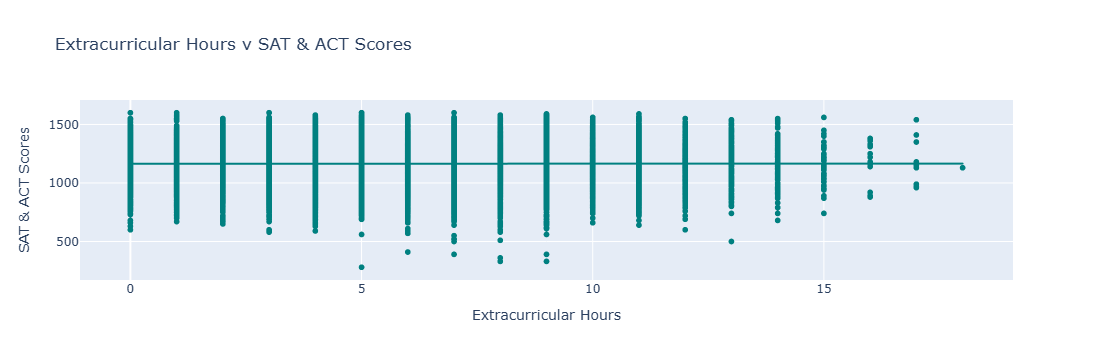

In [38]:
#Repeat with Plotly

#create scatter with trendline using plotly
fig = px.scatter( #creates scatter plot
    df, #with the data frame
    x = 'Extracurricular_Hours', #sets x variable
    y = 'SAT_ACT', #sets y variable
    trendline = 'ols', #creates a trendline using ordinary least squares technique
    color_discrete_sequence = ['teal'], #sets color to teal
    title = 'Extracurricular Hours v SAT & ACT Scores') #adds chart title

fig.update_layout( #updates chart layout, allowing axis titles
    xaxis_title='Extracurricular Hours', #sets x axis title
    yaxis_title='SAT & ACT Scores') #sets y axis title
fig.show() #displays chart


In [39]:
#There appears to be no clear replationship between SAT scores and Extracurricular activities as evidenced by the flat (slope = 0) trendline

In [42]:
#Part 5: What did we learn?
#I want to look  at admissions rates by college
admission_rates = (
    df.groupby("College")["Admitted"].apply(lambda x: (x == "Yes").mean()))

print("Admission Rates by College", admission_rates)

#And lets look at enrollment rates
enrollment_rates = (
    df.groupby("College")["Enrolled"].apply(lambda x: (x == "Yes").mean()))

print("\nEnrollment Rates by College", enrollment_rates)

Admission Rates by College College
Arts & Letters          0.249713
Business & Economics    0.358274
Math & Science          0.337054
Name: Admitted, dtype: float64

Enrollment Rates by College College
Arts & Letters          0.077685
Business & Economics    0.121618
Math & Science          0.077806
Name: Enrolled, dtype: float64


Findings:
Arts & Letters has the most applicants but the lowest admission and enrollment rate, how can we convert more admitted students to enrolled students?

Business & Economics has the highest enrollment rate at 12%, how can we attract more applicants to the college of Business & Economics?

Math & Science shares the highest median SAT_ACT score at 1,180, but only about 7.8% of its applicants enroll, how do we actualize more applicants?